# Phase 4 — Skill Network Analysis

**Research question:** Which technical skills are mentioned together, which skills occupy central or bridging positions, and which communities emerge?

This notebook builds a static, undirected, weighted network from **corrected Phase 2 skills**. It calculates graph metrics, detects communities, produces report figures and exports tables for Tableau. No API calls or salary modelling are required.

## Run instructions

1. Place `04_graph_analysis.ipynb` in your project root, beside `Datasets/` and `03_salary_model.py`.
2. Select your project Python kernel. If needed, install dependencies using the optional cell below.
3. Restart the kernel and **Run All**. Outputs are saved to `graph_results/` and overwritten on rerun.

The full job table supplies the demand denominator, including jobs with no corrected skill matches. The original `skills` column is deliberately not used. Graph calculations use all observed skills and all positive co-occurrences; only the network illustration hides weaker edges.

**Scope:** This notebook preserves your existing sample and duplicate-advertisement policy. Non-technical roles and repeated advertisements remain limitations. A skill mention is not necessarily a mandatory requirement. Network scores do not establish salary effects.

**Conclusion notes:** Each section ends with a short interpretation of the supplied-data results. These Markdown conclusions are written for this run; revise their numbers and wording if the input data or analytical settings change.

In [1]:
# Optional: uncomment and run once if imports fail, then restart the kernel.
# %pip install pandas numpy networkx matplotlib scipy

## 1. Configuration and project paths
The notebook can run from the project root or a subfolder beneath it. If automatic discovery fails, set `PROJECT_ROOT_OVERRIDE` to your project folder. Parameters below control presentation only, not the analytical graph.

In [2]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import json
import platform
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT_OVERRIDE = None  # Example: Path(r"C:\Users\leong\Documents\MyProject")
SEED = 42
DISPLAY_EDGE_QUANTILE = 0.80  # Draw the strongest 20% approximately; ties retained.
TOP_N = 15

if PROJECT_ROOT_OVERRIDE is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT_ROOT = next((p for p in candidates
                         if (p / 'Datasets/combined_data.csv').is_file()
                         and (p / 'Datasets/job_skills_clean.csv').is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError('Open from the project folder or set PROJECT_ROOT_OVERRIDE.')

DATA_DIR = PROJECT_ROOT / 'Datasets'
OUT_DIR = PROJECT_ROOT / 'graph_results'
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
print('Project:', PROJECT_ROOT)
print('Outputs:', OUT_DIR)
print('NetworkX:', nx.__version__)

DISPLAY_NAMES = {
    'python': 'Python', 'sql': 'SQL', 'r': 'R', 'go': 'Go', 'c++': 'C++', 'c#': 'C#',
    'aws': 'AWS', 'gcp': 'GCP', 'ci/cd': 'CI/CD', 'llm / genai': 'LLM / GenAI',
    'power bi': 'Power BI', 'pytorch': 'PyTorch', 'tensorflow': 'TensorFlow',
    'numpy': 'NumPy', 'javascript': 'JavaScript', 'typescript': 'TypeScript',
    'postgresql': 'PostgreSQL', 'mysql': 'MySQL', 'mongodb': 'MongoDB',
    'bigquery': 'BigQuery', 'scikit-learn': 'Scikit-Learn', 'nlp': 'NLP',
}
def label(skill):
    return DISPLAY_NAMES.get(skill, skill.title())

Project: /workspace/scratch/04ba14eb6936/tmp/latest/Web-analytics-project-1
Outputs: /workspace/scratch/04ba14eb6936/tmp/latest/Web-analytics-project-1/graph_results
NetworkX: 3.7


**Mini conclusion:** The notebook uses the corrected Phase 2 inputs and a fixed random seed of 42. Metrics are calculated on the full graph; the strongest-edge display setting affects only the figure, so simplifying the picture does not change the analytical results.

## 2. Load and validate the input tables
`job_uid` must uniquely identify a posting in the job table. Blank skills are excluded and repeated job–skill pairs are counted once. C++ and C# remain distinct; punctuation is not removed from canonical skill IDs.

In [3]:
def read_input(path):
    with path.open(encoding='utf-8-sig') as f:
        if f.readline().startswith('version https://git-lfs.github.com/spec/v1'):
            raise ValueError(f'{path.name} is a Git LFS pointer; obtain the actual CSV.')
    return pd.read_csv(path)

jobs = read_input(DATA_DIR / 'combined_data.csv')
skills = read_input(DATA_DIR / 'job_skills_clean.csv')
for table, required in [(jobs, {'job_uid'}), (skills, {'job_uid', 'skill'})]:
    missing = required - set(table.columns)
    if missing:
        raise ValueError(f'Missing columns: {missing}')
    if table['job_uid'].isna().any():
        raise ValueError('Missing job_uid values are not allowed.')
if jobs['job_uid'].duplicated().any():
    raise ValueError('The job metadata has duplicate job_uid values.')
if jobs.empty:
    raise ValueError('The job table is empty.')
if not skills['job_uid'].isin(jobs['job_uid']).all():
    raise ValueError('Some skill rows have no matching job metadata.')

skills['skill'] = skills['skill'].astype('string').str.strip().str.lower()
blank_rows = int((skills['skill'].isna() | skills['skill'].eq('')).sum())
skills = skills.loc[skills['skill'].notna() & skills['skill'].ne('')].copy()
duplicate_pairs = int(skills.duplicated(['job_uid', 'skill']).sum())
skills = skills.drop_duplicates(['job_uid', 'skill'])
if skills.empty:
    raise ValueError('No usable skill matches.')

total_jobs = len(jobs)
covered_jobs = skills['job_uid'].nunique()
coverage = pd.DataFrame([{
    'total_jobs': total_jobs, 'jobs_with_corrected_skills': covered_jobs,
    'jobs_without_corrected_skills': total_jobs-covered_jobs,
    'coverage_pct': 100*covered_jobs/total_jobs,
    'blank_skill_rows_removed': blank_rows,
    'duplicate_job_skill_pairs_removed': duplicate_pairs,
}])
display(coverage.round(2))
if 'source' in jobs:
    source_coverage = jobs.assign(has_corrected_skill=jobs['job_uid'].isin(skills['job_uid']))
    display(source_coverage.groupby('source').agg(
        total_jobs=('job_uid', 'size'), jobs_with_skills=('has_corrected_skill', 'sum')))
print('Coverage describes detected mentions, not extraction accuracy.')

Coverage describes detected mentions, not extraction accuracy.


,total_jobs,jobs_with_corrected_skills,jobs_without_corrected_skills,coverage_pct,blank_skill_rows_removed,duplicate_job_skill_pairs_removed
0,6869,5771,1098,84.02,0,0


,total_jobs,jobs_with_skills
source,,
himalayas,3469,3214
muse,3400,2557


**Mini conclusion:** Of the 6,869 postings, 5,771 (84.02%) contain at least one corrected skill match, while 1,098 contain none. The demand denominator remains 6,869, avoiding inflated percentages from dropping unmatched jobs. No blank skill rows or duplicate job–skill pairs required removal; this validates the mapping structure, not the accuracy of every extracted skill or the uniqueness of the underlying vacancies.

## 3. Count skills and pairs
Each job contributes at most one count to a skill and at most one count to each unordered skill pair.

For skills *i* and *j*, edge weight is their co-occurrence count. Jaccard similarity is:

`co-occurrence / (count_i + count_j - co-occurrence)`.

Raw weights measure volume; Jaccard adjusts for the individual frequencies of both skills.

In [4]:
skill_counts = skills.groupby('skill')['job_uid'].nunique().sort_index()
pair_counts = Counter()
for skill_list in skills.groupby('job_uid', sort=True)['skill']:
    pair_counts.update(combinations(sorted(set(skill_list[1])), 2))

edges = pd.DataFrame([
    {'skill_1': a, 'skill_2': b, 'job_count': count,
     'jaccard': count / (int(skill_counts[a])+int(skill_counts[b])-count),
     'distance': 1.0/count}
    for (a,b), count in sorted(pair_counts.items())
], columns=['skill_1', 'skill_2', 'job_count', 'jaccard', 'distance'])
frequency = skill_counts.rename('job_count').reset_index()
frequency['demand_pct'] = 100*frequency['job_count']/total_jobs
frequency['skill_label'] = frequency['skill'].map(label)
assert (edges['skill_1'] != edges['skill_2']).all()
assert not edges.duplicated(['skill_1','skill_2']).any()
assert edges['jaccard'].between(0,1).all()
display(edges.sort_values(['job_count','skill_1','skill_2'],
                          ascending=[False,True,True]).head(TOP_N))

,skill_1,skill_2,job_count,jaccard,distance
914,python,sql,1649,0.403474,0.000606
760,llm / genai,python,1054,0.265424,0.000949
118,aws,python,796,0.211702,0.001256
75,apache spark,python,742,0.215760,0.001348
89,aws,azure,738,0.445383,0.001355
140,azure,gcp,714,0.492754,0.001401
482,gcp,python,693,0.190857,0.001443
160,azure,python,681,0.180828,0.001468
350,ci/cd,python,670,0.181966,0.001493
98,aws,gcp,643,0.394721,0.001555


**Mini conclusion:** Python–SQL is the most frequent pair, appearing together in 1,649 postings, followed by Python–LLM / GenAI (1,054) and Python–AWS (796). Python–SQL has a Jaccard similarity of 0.403, showing substantial overlap without implying that the two skills always occur together. These counts describe mentions within advertisements, which may include optional or alternative skills.

## 4. Cross-check against Phase 2 exports
The check compares values by skill/pair, ignoring row order and ties. If it fails, resolve the inconsistent input versions before using the results. Missing optional reference files are reported, not silently treated as validated.

In [5]:
validation_messages = []
frequency_path = DATA_DIR / 'skill_frequency_stats.csv'
if frequency_path.exists():
    ref = read_input(frequency_path).set_index('skill').sort_index()
    actual = frequency.set_index('skill').sort_index()
    pd.testing.assert_frame_equal(actual[['job_count','demand_pct']],
                                  ref[['job_count','demand_pct']], check_dtype=False, check_index_type=False,
                                  check_exact=False, rtol=1e-8, atol=1e-8)
    validation_messages.append('PASS: Phase 2 skill frequencies and percentages match.')
else:
    validation_messages.append('SKIPPED: skill_frequency_stats.csv not provided.')
pair_path = DATA_DIR / 'skill_pair_stats.csv'
if pair_path.exists():
    ref = read_input(pair_path)
    canonical_pairs = [tuple(sorted((a,b))) for a,b in zip(ref['skill_1'],ref['skill_2'])]
    ref['skill_1'] = [p[0] for p in canonical_pairs]
    ref['skill_2'] = [p[1] for p in canonical_pairs]
    pd.testing.assert_frame_equal(
        edges.set_index(['skill_1','skill_2'])[['job_count','jaccard']].sort_index(),
        ref.set_index(['skill_1','skill_2'])[['job_count','jaccard']].sort_index(),
        check_dtype=False, check_index_type=False, check_exact=False, rtol=1e-8, atol=1e-8)
    validation_messages.append('PASS: Phase 2 pair counts and Jaccard similarities match.')
else:
    validation_messages.append('SKIPPED: skill_pair_stats.csv not provided.')
print('\n'.join(validation_messages))

PASS: Phase 2 skill frequencies and percentages match.
PASS: Phase 2 pair counts and Jaccard similarities match.


**Mini conclusion:** Both cross-checks pass: the reconstructed skill frequencies, demand percentages, pair counts and Jaccard similarities match Phase 2. The graph therefore uses a consistent version of the corrected skill data. Agreement between calculations does not remove the upstream sampling and extraction limitations.

## 5. Construct the analytical graph
All detected skills are added, including isolates. Edges are undirected because appearing together does not imply direction. No weak edges are removed for metrics.

`weight` represents strength; `distance = 1 / weight` represents shortest-path cost. Using raw counts as shortest-path distances would make stronger relationships longer.

In [6]:
G = nx.Graph(sample='full_corrected_skill_sample', total_jobs=int(total_jobs))
for row in frequency.itertuples(index=False):
    G.add_node(row.skill, label=row.skill_label, job_count=int(row.job_count),
               demand_pct=float(row.demand_pct))
for row in edges.itertuples(index=False):
    G.add_edge(row.skill_1,row.skill_2,weight=int(row.job_count),
               jaccard=float(row.jaccard),distance=float(row.distance))
node_count, edge_count = G.number_of_nodes(), G.number_of_edges()
print(f'{node_count} skills; {edge_count} edges; density = {nx.density(G):.3f}')
print('Connected components:', nx.number_connected_components(G))
print('Isolated skills:', list(nx.isolates(G)))

46 skills; 995 edges; density = 0.961
Connected components: 1
Isolated skills: []


**Mini conclusion:** The network has 46 skill nodes and 995 edges out of 1,035 possible pairs, giving a density of 0.961. All skills belong to one connected component and there are no isolates. Because almost every pair is connected, the strength of connections is more informative than simply whether a connection exists.

## 6. Centrality measures

| Metric | Meaning in this network |
|---|---|
| Degree centrality | Fraction of other skills connected to a skill |
| Weighted degree | Total pair counts incident to a skill; not a count of distinct jobs |
| PageRank | Weighted connectivity to other well-connected skills, with damping 0.85 |
| Betweenness | Share of shortest paths passing through a skill, using inverse-count distances |

Weighted degree counts a job multiple times if it contains several neighbours. High centrality is not proof of a mandatory skill, causal influence or a salary premium. In a dense network degree centrality can be similar across many skills; PageRank and weighted degree may also be closely related.

In [7]:
degree = nx.degree_centrality(G) if node_count > 1 else {n:0.0 for n in G}
weighted_degree = dict(G.degree(weight='weight'))
pagerank = nx.pagerank(G, alpha=0.85, weight='weight', max_iter=1000, tol=1e-12)
betweenness = nx.betweenness_centrality(G, normalized=True, weight='distance')
centrality = frequency.copy()
centrality['degree'] = centrality['skill'].map(dict(G.degree()))
centrality['degree_centrality'] = centrality['skill'].map(degree)
centrality['weighted_degree'] = centrality['skill'].map(weighted_degree)
centrality['pagerank'] = centrality['skill'].map(pagerank)
centrality['betweenness'] = centrality['skill'].map(betweenness)
assert np.isclose(sum(pagerank.values()), 1.0)
assert sum(weighted_degree.values()) == 2*sum(pair_counts.values())
for metric in ['weighted_degree','pagerank','betweenness']:
    print('Top skills by',metric)
    display(centrality.sort_values([metric,'skill'],ascending=[False,True])[
        ['skill_label','job_count','demand_pct',metric]].head(10).round(5))

Top skills by weighted_degree
Top skills by pagerank
Top skills by betweenness


,skill_label,job_count,demand_pct,weighted_degree
32,Python,3304,48.10016,16107
41,SQL,2432,35.40544,11143
23,LLM / GenAI,1721,25.05459,7986
2,AWS,1252,18.22682,7815
3,Azure,1143,16.63998,7393
12,GCP,1020,14.84932,7018
8,CI/CD,1048,15.25695,6585
1,Apache Spark,877,12.76751,6377
17,Java,833,12.12695,5296
20,Kubernetes,691,10.05969,4779


,skill_label,job_count,demand_pct,pagerank
32,Python,3304,48.10016,0.09375
41,SQL,2432,35.40544,0.06515
23,LLM / GenAI,1721,25.05459,0.04774
2,AWS,1252,18.22682,0.04660
3,Azure,1143,16.63998,0.04389
12,GCP,1020,14.84932,0.04203
8,CI/CD,1048,15.25695,0.03980
1,Apache Spark,877,12.76751,0.03838
17,Java,833,12.12695,0.03261
20,Kubernetes,691,10.05969,0.02994


,skill_label,job_count,demand_pct,betweenness
32,Python,3304,48.10016,0.87778
41,SQL,2432,35.40544,0.21414
23,LLM / GenAI,1721,25.05459,0.04444
43,TensorFlow,518,7.54113,0.04343
1,Apache Spark,877,12.76751,0.00101
0,Airflow,338,4.92066,0.00000
2,AWS,1252,18.22682,0.00000
3,Azure,1143,16.63998,0.00000
4,Bash/Shell,241,3.50852,0.00000
5,BigQuery,255,3.71233,0.00000


**Mini conclusion:** Python leads weighted degree (16,107), PageRank (0.09375) and weighted betweenness (0.87778), with SQL second in each measure. Python therefore occupies a central and bridging position under this graph's weighting assumptions. However, 24 skills connect to all 45 other skills, making degree centrality alone a poor discriminator; PageRank and weighted degree also reflect overlapping evidence rather than independent confirmation. Betweenness is sensitive to the inverse-count distance definition.

## 7. Community detection
Louvain optimises weighted modularity. Community IDs are arbitrary labels, not rankings. Fixed seed and sorted graph insertion improve reproducibility; package versions can still affect results.

Describe each group from its actual membership rather than imposing desired labels. Standard Louvain gives each skill one community even when that skill is used across several professional fields. Modularity describes separation under this graph and weighting; it does not certify meaningful occupational clusters.

In [8]:
if edge_count:
    groups = nx.community.louvain_communities(G, weight='weight', resolution=1, seed=SEED)
    groups = sorted(groups, key=lambda group: (-len(group), tuple(sorted(group))))
    modularity = nx.community.modularity(G, groups, weight='weight')
else:
    groups = [{skill} for skill in sorted(G)]
    modularity = None
membership = {skill:i+1 for i,group in enumerate(groups) for skill in group}
centrality['community_id'] = centrality['skill'].map(membership)
centrality['community_label'] = centrality['community_id'].map(lambda x:f'Community {x}')
community_rows = []
for i, group in enumerate(groups,1):
    ordered = sorted(group,key=lambda s:(-int(skill_counts[s]),s))
    job_count = skills.loc[skills['skill'].isin(group),'job_uid'].nunique()
    community_rows.append({'community_id':i,'community_label':f'Community {i}',
        'number_of_skills':len(group),'jobs_mentioning_any_member':job_count,
        'share_of_all_jobs_pct':100*job_count/total_jobs,
        'top_skills':', '.join(label(s) for s in ordered[:8]),
        'all_skills':', '.join(label(s) for s in ordered)})
community_summary = pd.DataFrame(community_rows)
print('Weighted modularity:', None if modularity is None else round(modularity,4))
display(community_summary.drop(columns='all_skills').round(2))
print('Jobs may mention several communities; community job counts are not additive.')

Weighted modularity: 0.117
Jobs may mention several communities; community job counts are not additive.


,community_id,community_label,number_of_skills,jobs_mentioning_any_member,share_of_all_jobs_pct,top_skills
0,1,Community 1,21,3630,52.85,"AWS, Azure, CI/CD, GCP, Java, Kubernetes, Git,..."
1,2,Community 2,14,4509,65.64,"Python, SQL, Apache Spark, R, Tableau, Power B..."
2,3,Community 3,11,2163,31.49,"LLM / GenAI, TensorFlow, PyTorch, NLP, Compute..."


**Mini conclusion:** Louvain identifies three groups: Community 1 contains 21 skills broadly associated with cloud platforms and software infrastructure; Community 2 contains 14 skills spanning data engineering, analytics and BI; Community 3 contains 11 skills associated with AI/ML and scientific Python tools. These are descriptive interpretations of the memberships, not predefined occupational categories. Modularity is only 0.117, indicating modest separation: the groups have substantial connections between them. Community 2 reaches the most postings (4,509; 65.64%), but posting membership can overlap across communities.

## 8. Static network illustration
Node size shows posting count; colour shows Louvain community. Edge thickness shows co-occurrence volume. Only the strongest edges are drawn to reduce clutter. **The layout, metrics and communities use the full graph.** A node with no visible edges may still be connected analytically.

This image is a fixed full-sample result for the report and Tableau. Dashboard filters cannot recalculate it.

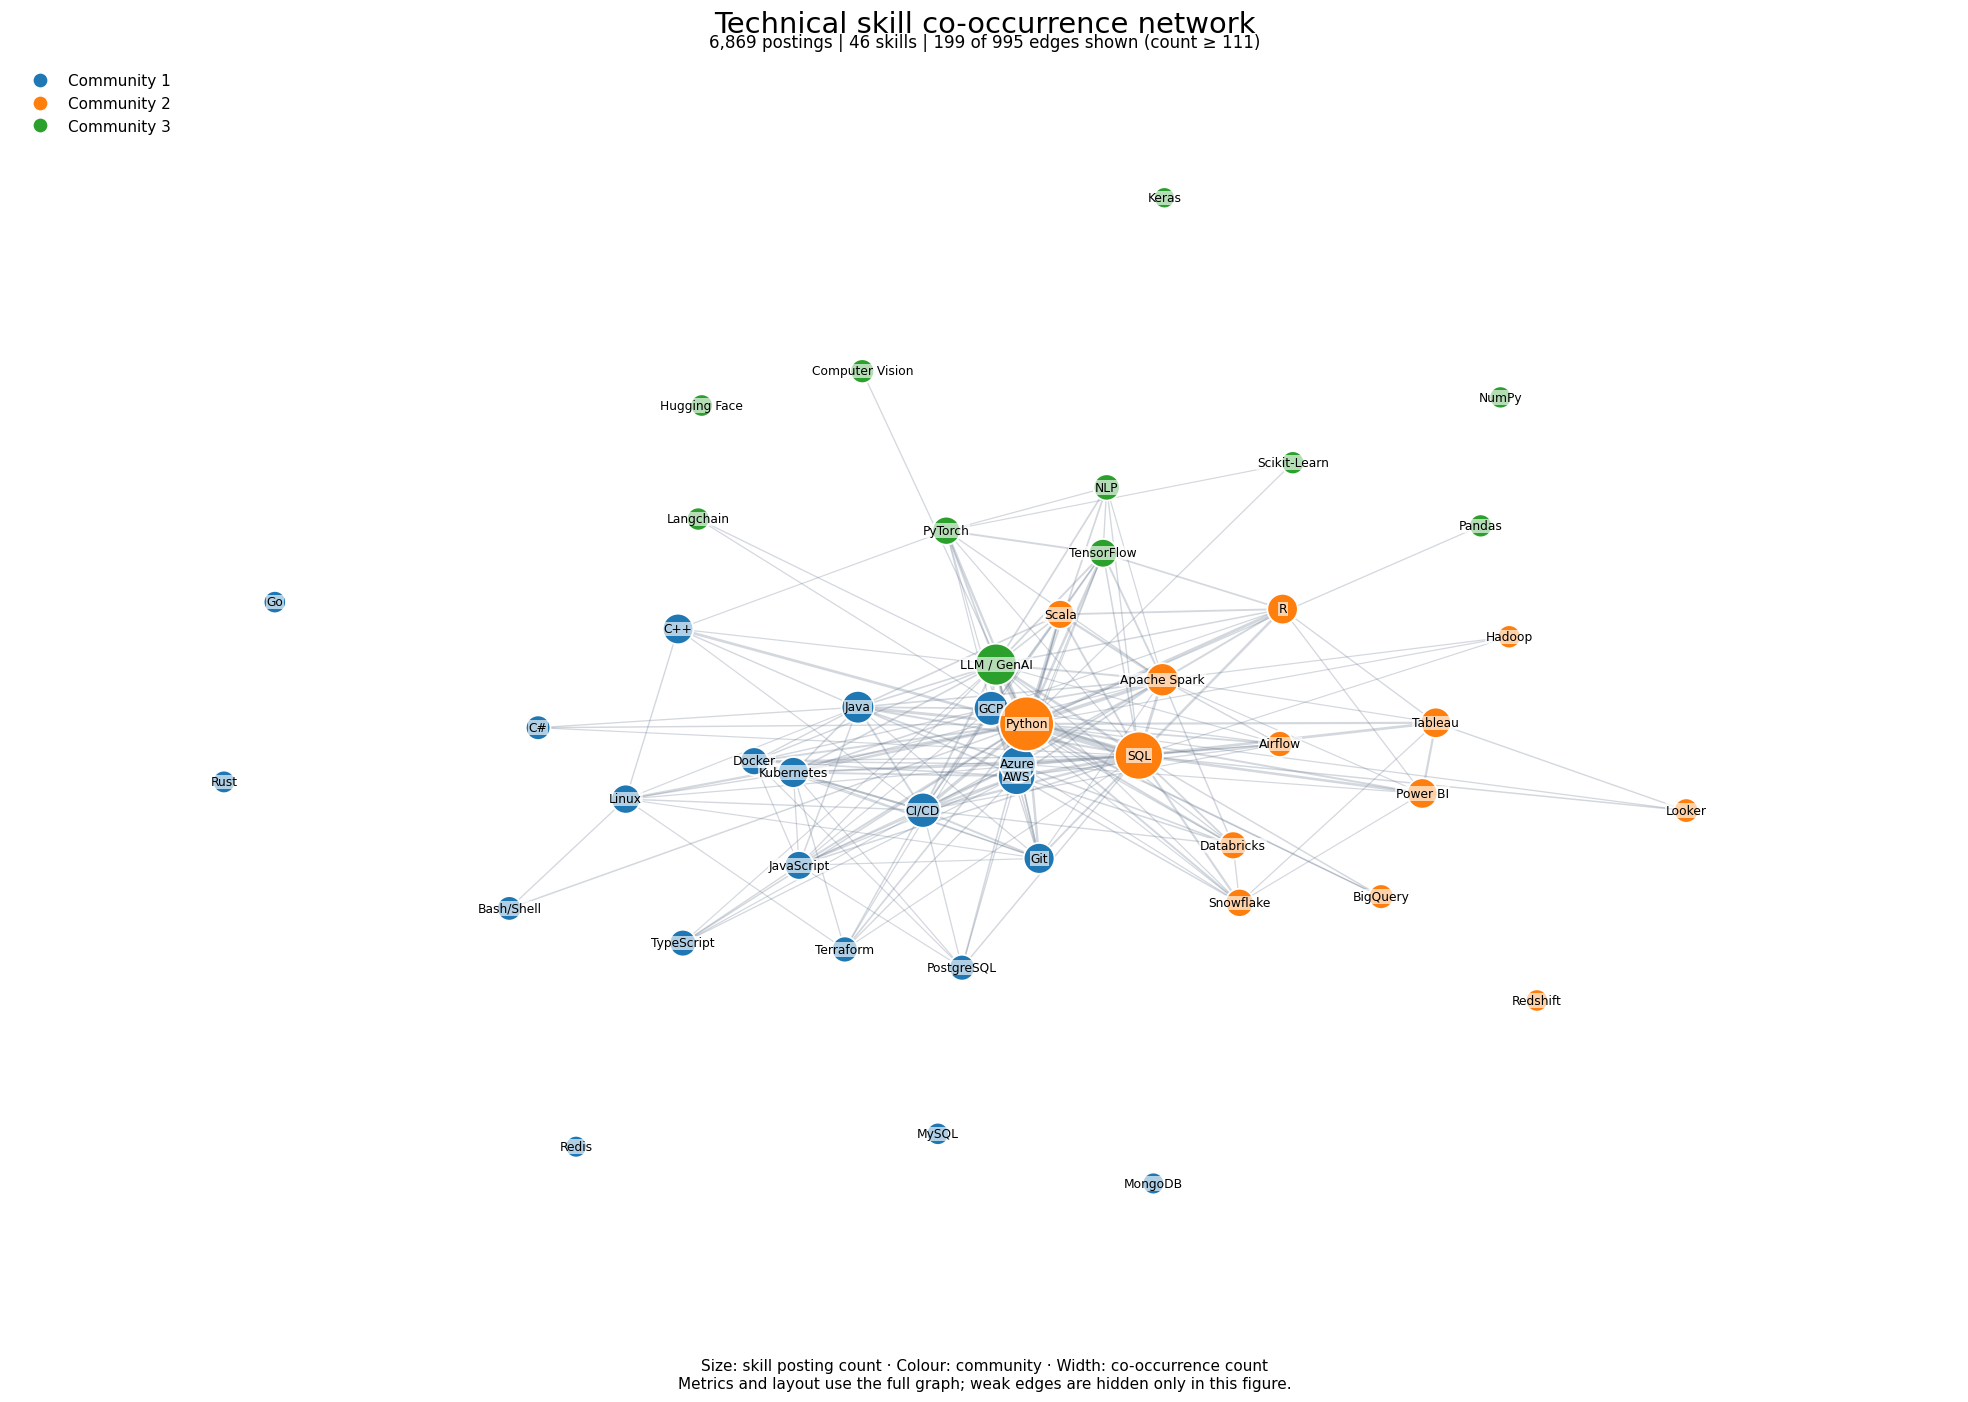

In [9]:
pos = nx.spring_layout(G, seed=SEED, weight='weight', iterations=300)
threshold = float(np.ceil(edges['job_count'].quantile(DISPLAY_EDGE_QUANTILE))) if edge_count else 0
visible_edges = [(a,b) for a,b,d in G.edges(data=True) if d['weight'] >= threshold]
colors = {i:matplotlib.colormaps['tab10']((i-1)%10) for i in range(1,len(groups)+1)}
max_count = float(skill_counts.max())
node_sizes = [180+1100*G.nodes[s]['job_count']/max_count for s in G]
max_weight = max((d['weight'] for _,_,d in G.edges(data=True)),default=1)
fig,ax = plt.subplots(figsize=(18,13))
nx.draw_networkx_edges(G,pos,edgelist=visible_edges,
    width=[0.5+4*G[a][b]['weight']/max_weight for a,b in visible_edges],
    edge_color='#64748b',alpha=0.28,ax=ax)
nx.draw_networkx_nodes(G,pos,node_size=node_sizes,
    node_color=[colors[membership[s]] for s in G],edgecolors='white',linewidths=1.2,ax=ax)
nx.draw_networkx_labels(G,pos,labels={s:label(s) for s in G},font_size=8,
    bbox={'facecolor':'white','edgecolor':'none','alpha':0.65,'pad':0.5},ax=ax)
handles=[plt.Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i],
                   markersize=10,label=f'Community {i}') for i in colors]
ax.legend(handles=handles,loc='upper left',frameon=False)
ax.set_title('Technical skill co-occurrence network',fontsize=19,pad=18)
ax.text(0.5,1.01,f'{total_jobs:,} postings | {node_count} skills | '
        f'{len(visible_edges)} of {edge_count} edges shown (count ≥ {threshold:g})',
        transform=ax.transAxes,ha='center',fontsize=11)
ax.axis('off'); ax.margins(0.14)
fig.text(0.5,0.025,'Size: skill posting count · Colour: community · Width: co-occurrence count\n'
         'Metrics and layout use the full graph; weak edges are hidden only in this figure.',
         ha='center',fontsize=10)
fig.tight_layout(rect=(0,0.06,1,1))
fig.savefig(FIG_DIR/'skill_network.png',dpi=220,bbox_inches='tight')
plt.show()

**Mini conclusion:** The illustration displays 199 of the 995 edges, retaining pairs appearing in at least 111 postings. This makes strong connections around the major skills easier to inspect while keeping all 46 nodes visible. A skill that appears isolated in this picture is not necessarily isolated in the analytical graph: weaker edges are hidden, and all metrics still use the full network.

## 9. Supporting charts
Rankings remain readable even when the network is dense. The second figure shows community composition, not a distribution of mutually exclusive jobs.

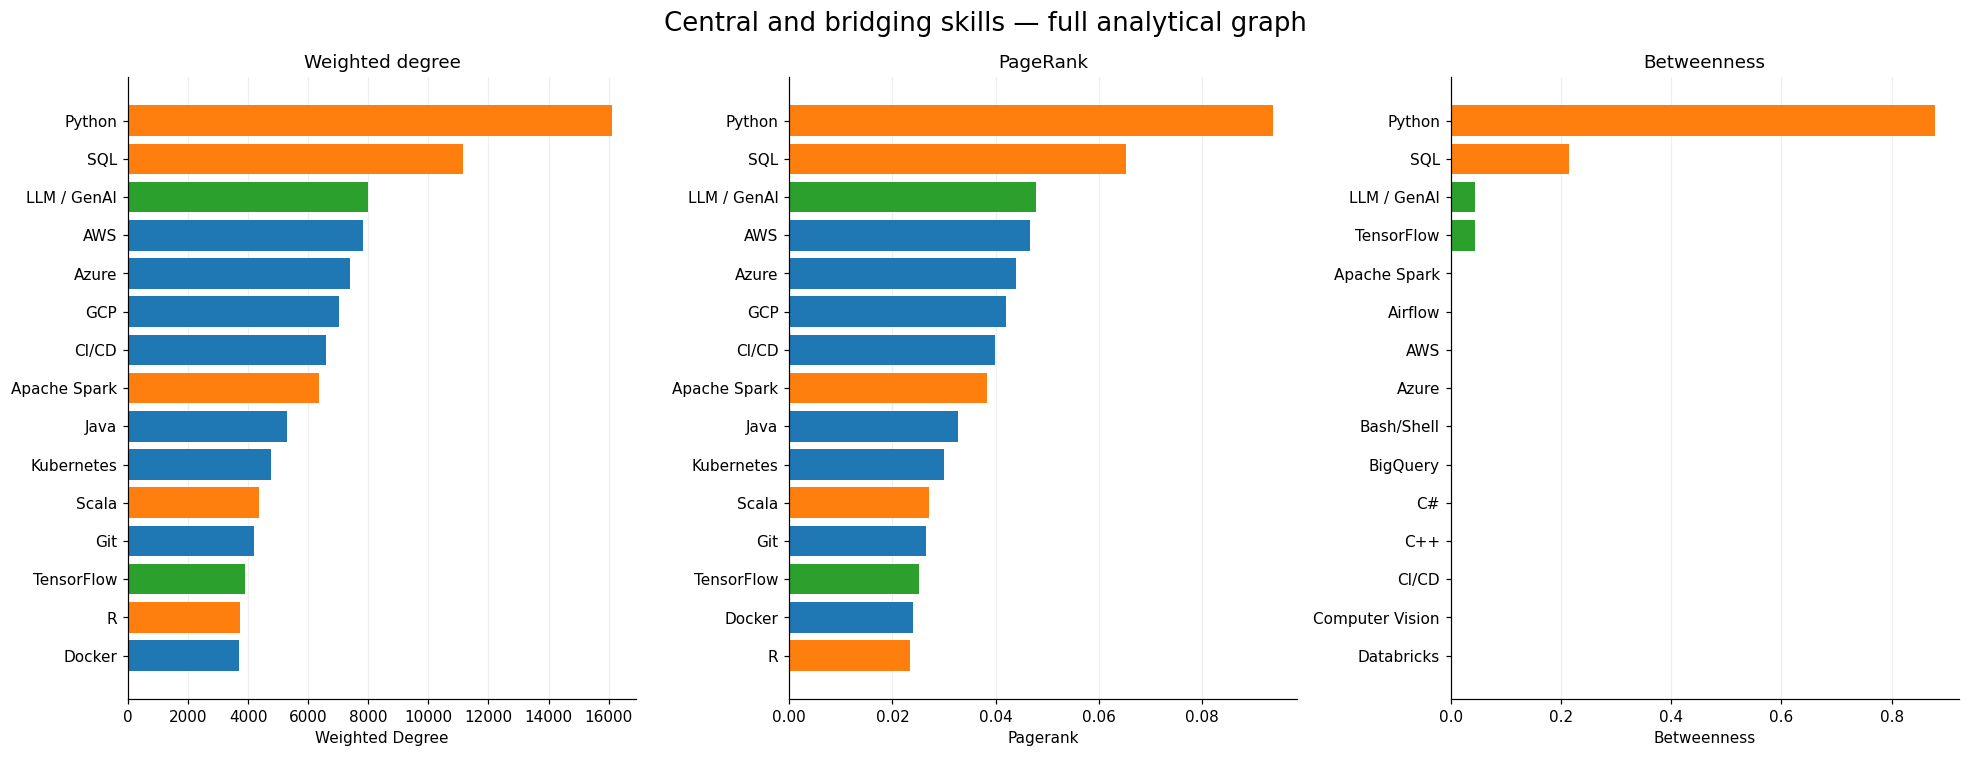

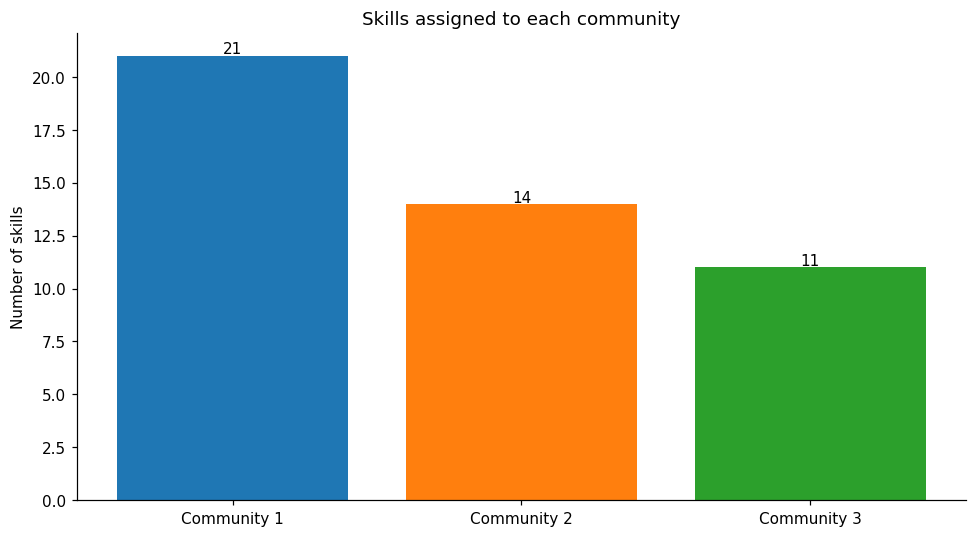

In [10]:
fig,axes = plt.subplots(1,3,figsize=(18,7))
for ax,metric,title in zip(axes,['weighted_degree','pagerank','betweenness'],
                          ['Weighted degree','PageRank','Betweenness']):
    top = centrality.sort_values([metric,'skill'],ascending=[False,True]).head(TOP_N).iloc[::-1]
    ax.barh(top['skill_label'],top[metric],color=[colors[i] for i in top['community_id']])
    ax.set_title(title); ax.set_xlabel(metric.replace('_',' ').title())
    ax.grid(axis='x',alpha=0.2);ax.set_axisbelow(True)
fig.suptitle('Central and bridging skills — full analytical graph',fontsize=17)
fig.tight_layout()
fig.savefig(FIG_DIR/'centrality_rankings.png',dpi=200,bbox_inches='tight')
plt.show()

fig,ax = plt.subplots(figsize=(9,5))
ax.bar(community_summary['community_label'],community_summary['number_of_skills'],
       color=[colors[i] for i in community_summary['community_id']])
ax.set_ylabel('Number of skills');ax.set_title('Skills assigned to each community')
for i,row in community_summary.iterrows():
    ax.text(i,row['number_of_skills']+0.1,str(row['number_of_skills']),ha='center')
fig.tight_layout();fig.savefig(FIG_DIR/'community_sizes.png',dpi=200,bbox_inches='tight')
plt.show()

**Mini conclusion:** The ranking charts confirm that Python and SQL dominate weighted connectivity, while weighted betweenness is particularly concentrated in Python. The community-size chart shows 21, 14 and 11 skills in the three groups. These are counts of skill nodes, so a larger community should not be interpreted automatically as having more job opportunities or higher salaries.

## 10. Findings and interpretation
The next cell derives factual summaries from this run. Use the accompanying prompts to develop the discussion rather than treating network rankings as career advice.

In [11]:
top_demand = centrality.sort_values(['job_count','skill'],ascending=[False,True]).iloc[0]
top_bridge = centrality.sort_values(['betweenness','skill'],ascending=[False,True]).iloc[0]
top_pr = centrality.sort_values(['pagerank','skill'],ascending=[False,True]).iloc[0]
lines = [
    f"- **Coverage:** {covered_jobs:,} of {total_jobs:,} postings ({100*covered_jobs/total_jobs:.2f}%) contain a corrected skill match.",
    f"- **Demand:** {top_demand['skill_label']} is the most frequent detected skill ({int(top_demand['job_count']):,} postings; {top_demand['demand_pct']:.2f}% of all postings).",
    f"- **Connectivity:** {top_pr['skill_label']} ranks first in weighted PageRank.",
    f"- **Bridging:** {top_bridge['skill_label']} ranks first in inverse-count-weighted betweenness ({top_bridge['betweenness']:.4f}).",
    f"- **Structure:** {len(groups)} communities; graph density {nx.density(G):.3f}."
]
if modularity is not None:
    lines.append(f'- **Separation:** weighted modularity is {modularity:.3f}; inspect memberships before assigning professional labels.')
display(Markdown('\n'.join(lines)))
for row in community_summary.itertuples(index=False):
    display(Markdown(f'**{row.community_label}:** {row.all_skills}'))

- **Coverage:** 5,771 of 6,869 postings (84.02%) contain a corrected skill match.
- **Demand:** Python is the most frequent detected skill (3,304 postings; 48.10% of all postings).
- **Connectivity:** Python ranks first in weighted PageRank.
- **Bridging:** Python ranks first in inverse-count-weighted betweenness (0.8778).
- **Structure:** 3 communities; graph density 0.961.
- **Separation:** weighted modularity is 0.117; inspect memberships before assigning professional labels.

**Community 1:** AWS, Azure, CI/CD, GCP, Java, Kubernetes, Git, C++, Linux, JavaScript, Docker, TypeScript, Terraform, PostgreSQL, C#, Bash/Shell, Rust, Go, MySQL, MongoDB, Redis

**Community 2:** Python, SQL, Apache Spark, R, Tableau, Power BI, Scala, Snowflake, Databricks, Airflow, BigQuery, Looker, Hadoop, Redshift

**Community 3:** LLM / GenAI, TensorFlow, PyTorch, NLP, Computer Vision, Langchain, Scikit-Learn, Pandas, Hugging Face, NumPy, Keras

### Discussion prompts

- Does the highest-demand skill also rank highest in PageRank? Explain any agreement without treating the metrics as independent evidence.
- Which skills bridge communities? Betweenness depends on the inverse-count distance assumption and may favour very frequent skills.
- What descriptive name fits each community's membership? Broad membership or weak separation should be reported honestly.
- Compare raw pair counts with Jaccard: high-volume pairs need not have the strongest normalised overlap.
- Do not infer a salary premium from network centrality. Salary conclusions belong to the separate controlled model and its confidence intervals.

### Limitations to report

The graph reflects the selected sources, repeated advertisements, upstream sampling and the skill dictionary. It includes the job-relevance limitations already identified in earlier phases. The stricter Go/R patterns reduce false positives but may miss genuine mentions. Co-occurrence can represent alternatives (e.g. “AWS or Azure”) rather than complementary requirements. Communities are descriptive and sensitive to weighting, source composition and algorithm settings. All outputs below refer to the full analytical sample, not a dynamically filtered Tableau selection.

**Mini conclusion:** The results portray a strongly interconnected skill ecosystem centred on Python and SQL, with broad cloud/software, data/BI and AI/ML groupings. The clearest finding is the importance of weighted relationships within a dense network, rather than sharply separated communities. These patterns describe the selected postings and dictionary; they do not establish mandatory skill combinations, causal importance or salary benefits.

## 11. Export results for Tableau and the report
`skill` is the stable Phase 2 identifier; `skill_label` is for display. GraphML preserves the analytical graph. The exported layout and display flag document the static figure; they do not change graph metrics.

Community labels are intentionally neutral. You may add defensible descriptive names after inspecting memberships. Do not sum `jobs_mentioning_any_member` across communities because one posting can contribute to several groups.

In [12]:
centrality = centrality.sort_values(['pagerank','skill'],ascending=[False,True]).reset_index(drop=True)
communities = centrality[['skill','skill_label','community_id','community_label']].sort_values(['community_id','skill'])
layout = pd.DataFrame([{'skill':s,'skill_label':label(s),'x':float(pos[s][0]),'y':float(pos[s][1])}
                       for s in sorted(G)])
edges_export = edges.copy()
edges_export['skill_1_label'] = edges_export['skill_1'].map(label)
edges_export['skill_2_label'] = edges_export['skill_2'].map(label)
edges_export['shown_in_static_figure'] = edges_export['job_count'] >= threshold
for row in centrality.itertuples(index=False):
    G.nodes[row.skill].update(degree=int(row.degree),degree_centrality=float(row.degree_centrality),
        weighted_degree=int(row.weighted_degree),pagerank=float(row.pagerank),
        betweenness=float(row.betweenness),community_id=int(row.community_id),
        community_label=row.community_label)

summary = {'total_jobs':int(total_jobs),'jobs_with_corrected_skills':int(covered_jobs),
    'nodes':node_count,'edges':edge_count,'density':nx.density(G),
    'connected_components':nx.number_connected_components(G),'isolates':nx.number_of_isolates(G),
    'communities':len(groups),'modularity':modularity,'display_edge_threshold':threshold,
    'displayed_edges':len(visible_edges)}
tables = {'centrality_results.csv':centrality,'communities.csv':communities,
          'community_summary.csv':community_summary,'network_edges.csv':edges_export,
          'node_layout.csv':layout,'coverage_summary.csv':coverage,
          'network_summary.csv':pd.DataFrame([summary])}
for filename,table in tables.items():
    table.to_csv(OUT_DIR/filename,index=False)
nx.write_graphml(G,OUT_DIR/'skill_network.graphml')
loaded = nx.read_graphml(OUT_DIR/'skill_network.graphml')
assert loaded.number_of_nodes()==node_count and loaded.number_of_edges()==edge_count
metadata = {'sample':'full corrected-skill sample; no salary restriction',
    'inputs':['Datasets/combined_data.csv','Datasets/job_skills_clean.csv'],
    'seed':SEED,'analytical_edge_threshold':1,'display_edge_quantile':DISPLAY_EDGE_QUANTILE,
    'pagerank_alpha':0.85,'betweenness_distance':'1 / cooccurrence count',
    'community_method':'Louvain, weight=count, resolution=1',
    'versions':{'python':platform.python_version(),'pandas':pd.__version__,
                'numpy':np.__version__,'networkx':nx.__version__,'matplotlib':matplotlib.__version__},
    'validation':validation_messages}
(OUT_DIR/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
(OUT_DIR/'TABLEAU_GUIDE.md').write_text("""# Tableau use

- Use centrality_results.csv for centrality rankings and skill demand (one row per skill).
- Use communities.csv to relate skill IDs to community membership if needed.
- Use community_summary.csv for group summaries. Jobs can belong to several communities.
- Add figures/skill_network.png as an image; label it Full-sample skill network.
- network_edges.csv contains one row per skill pair; do not join it directly to job rows and then sum job counts.
- Metrics are precomputed for the full sample. Filtering displayed skills does not recompute PageRank, betweenness or communities.
- Use corrected Phase 3 salary outputs for salary charts; these graph files do not contain salary estimates.
- Preserve C++ and C# as separate keys when relating to the salary results.
""",encoding='utf-8')
print('Exported files:')
for path in sorted(OUT_DIR.rglob('*')):
    if path.is_file():print(path.relative_to(PROJECT_ROOT))

Exported files:
graph_results/TABLEAU_GUIDE.md
graph_results/centrality_results.csv
graph_results/communities.csv
graph_results/community_summary.csv
graph_results/coverage_summary.csv
graph_results/figures/centrality_rankings.png
graph_results/figures/community_sizes.png
graph_results/figures/skill_network.png
graph_results/network_edges.csv
graph_results/network_summary.csv
graph_results/node_layout.csv
graph_results/run_metadata.json
graph_results/skill_network.graphml


**Mini conclusion:** The analysis exports seven CSV tables, the full GraphML network, three static figures, run metadata and a Tableau guide. Together they support reproducible reporting and the dashboard's network section. Centrality and community results describe the full sample: filtering these exported rows in Tableau does not recalculate the underlying network.